# 📐 Linear Algebra for AI & Machine Learning
> **The Mathematical Foundation of Embeddings, Neural Networks, Transformers & Optimization**

---

### 🌟 Why Linear Algebra is the Core of AI
In modern artificial intelligence, **data is represented as vectors, models are parameterized as matrices, and computations are expressed as tensor transformations**.
Whether you are passing a prompt into an LLM, computing attention weights, fine-tuning with LoRA, or optimizing loss via gradient descent, linear algebra is running beneath the surface.

```
┌──────────────────────────────────────────────────────────────────────────────────────────┐
│                                 LINEAR ALGEBRA IN AI                                     │
├─────────────────────────┬───────────────────────────────┬────────────────────────────────┤
│ Concept                 │ Mathematical Object           │ Concrete AI / ML Application   │
├─────────────────────────┼───────────────────────────────┼────────────────────────────────┤
│ Vector & Norms          │ v ∈ ℝⁿ, ||v||₂                │ Word / Document Embeddings     │
│ Dot Product & Cosine    │ a · b = ||a|| ||b|| cos(θ)    │ Scaled Dot-Product Attention   │
│ Matrix Transformations  │ y = Wx + b                    │ Neural Network Dense Layers    │
│ Linear Independence     │ c₁v₁ + c₂v₂ = 0 ⇒ cᵢ=0        │ Feature Correlation / OLS      │
│ Matrix Rank & LoRA      │ rank(W) ≤ min(m, n)           │ Parameter-Efficient Fine-Tuning│
│ Projections             │ P = A(AᵀA)⁻¹Aᵀ                │ Linear Regression & PCA        │
│ Eigenvalues / Vectors   │ Av = λv                       │ PCA & Dimensionality Reduction │
└─────────────────────────┴───────────────────────────────┴────────────────────────────────┘
```

---
## 1. 🏹 Vectors: Points, Directions & Norms

### 1.1 Mathematical Representation
A vector $\mathbf{x} \in \mathbb{R}^n$ is an ordered $n$-tuple of real numbers. Geometrically, it represents both a **point** in $n$-dimensional space and an **arrow (direction + magnitude)** from the origin:

$$\mathbf{x} = \begin{bmatrix} x_1 \\ x_2 \\ \vdots \\ x_n \end{bmatrix} \in \mathbb{R}^n$$

### 1.2 Vector Norms (Measuring Magnitude)
A **norm** $\|\mathbf{x}\|$ maps a vector to a non-negative scalar representing its length or size.

1. **$L_2$ Norm (Euclidean Distance / Euclidean Norm):**
   $$\|\mathbf{x}\|_2 = \sqrt{\sum_{i=1}^n x_i^2} = \sqrt{\mathbf{x}^T \mathbf{x}}$$
   *Used in:* Weight decay ($L_2$ regularization / Ridge), gradient clipping, cosine similarity.

2. **$L_1$ Norm (Manhattan / Taxicab Norm):**
   $$\|\mathbf{x}\|_1 = \sum_{i=1}^n |x_i|$$
   *Used in:* Lasso regularization (induces weight sparsity for feature selection), robust loss functions (MAE).

3. **$L_\infty$ Norm (Max / Chebyshev Norm):**
   $$\|\mathbf{x}\|_\infty = \max_{1 \le i \le n} |x_i|$$
   *Used in:* Adversarial robustness attacks (e.g., FGSM $\epsilon$-perturbation bounds).

4. **Unit Normalization ($\hat{\mathbf{x}}$):**
   $$\hat{\mathbf{x}} = \frac{\mathbf{x}}{\|\mathbf{x}\|_2} \quad \implies \quad \|\hat{\mathbf{x}}\|_2 = 1$$
   *Used in:* Normalizing embeddings before cosine similarity calculations in Vector DBs.

> 💡 **AI Intuition:** A 1536-dimensional OpenAI text embedding or 4096-dimensional LLaMA-3 hidden state is simply a vector $\mathbf{v} \in \mathbb{R}^{4096}$ where each dimension captures an abstract semantic feature.

--- Vector Analysis for v1 = [3, 4] ---
L1 Norm (Manhattan):   7.00
L2 Norm (Euclidean):   5.00
L∞ Norm (Maximum):     4.00
Unit Vector (v1 / ||v1||): [0.6 0.8] (L2 Norm: 1.00)


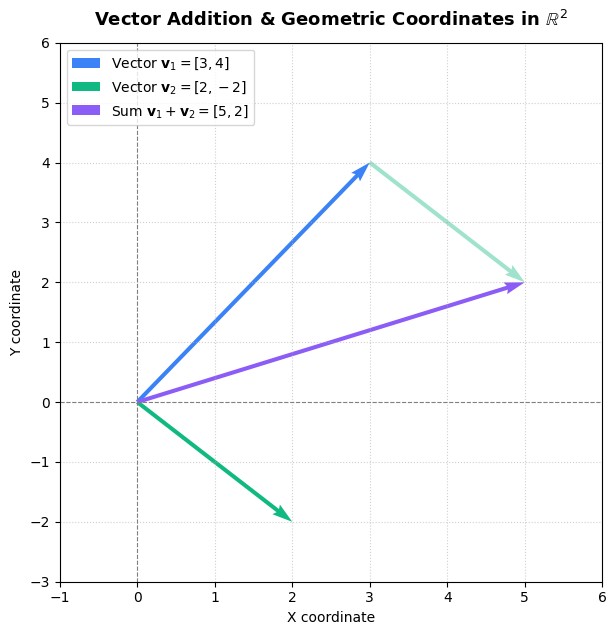

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Define 2D sample vectors
v1 = np.array([3, 4])
v2 = np.array([2, -2])
v_sum = v1 + v2

# Calculate Vector Norms
l1_norm = np.linalg.norm(v1, ord=1)
l2_norm = np.linalg.norm(v1, ord=2)
linf_norm = np.linalg.norm(v1, ord=np.inf)
unit_v1 = v1 / l2_norm

print("--- Vector Analysis for v1 = [3, 4] ---")
print(f"L1 Norm (Manhattan):   {l1_norm:.2f}")
print(f"L2 Norm (Euclidean):   {l2_norm:.2f}")
print(f"L∞ Norm (Maximum):     {linf_norm:.2f}")
print(f"Unit Vector (v1 / ||v1||): {unit_v1} (L2 Norm: {np.linalg.norm(unit_v1):.2f})")

# Visualization: 2D Vectors & Vector Addition
fig, ax = plt.subplots(figsize=(7, 7))
ax.quiver(0, 0, v1[0], v1[1], angles='xy', scale_units='xy', scale=1, color='#3B82F6', label=r'Vector $\mathbf{v}_1 = [3, 4]$')
ax.quiver(0, 0, v2[0], v2[1], angles='xy', scale_units='xy', scale=1, color='#10B981', label=r'Vector $\mathbf{v}_2 = [2, -2]$')
ax.quiver(v1[0], v1[1], v2[0], v2[1], angles='xy', scale_units='xy', scale=1, color='#10B981', alpha=0.4, linestyle='dashed')
ax.quiver(0, 0, v_sum[0], v_sum[1], angles='xy', scale_units='xy', scale=1, color='#8B5CF6', label=r'Sum $\mathbf{v}_1 + \mathbf{v}_2 = [5, 2]$')

ax.set_xlim(-1, 6)
ax.set_ylim(-3, 6)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
ax.grid(True, linestyle=':', alpha=0.6)
ax.set_title("Vector Addition & Geometric Coordinates in $\mathbb{R}^2$", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.legend(loc='upper left', frameon=True)
plt.show()

---
## 2. ⚡ The Dot Product & Cosine Similarity

### 2.1 The Core Equations
The dot product (inner product) is the single most important vector operation in Machine Learning.

1. **Algebraic Definition:**
   $$\mathbf{a} \cdot \mathbf{b} = \mathbf{a}^T \mathbf{b} = \sum_{i=1}^n a_i b_i = a_1 b_1 + a_2 b_2 + \dots + a_n b_n$$

2. **Geometric Definition:**
   $$\mathbf{a} \cdot \mathbf{b} = \|\mathbf{a}\|_2 \|\mathbf{b}\|_2 \cos(\theta)$$
   where $\theta$ is the angle between vectors $\mathbf{a}$ and $\mathbf{b}$.

3. **Cosine Similarity:**
   $$\text{Cosine Similarity}(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\|_2 \|\mathbf{b}\|_2} = \cos(\theta) \in [-1, 1]$$

### 2.2 Geometric Meaning & Alignment Table
| Angle $\theta$ | $\cos(\theta)$ | $\mathbf{a} \cdot \mathbf{b}$ Sign | Semantic / Geometric Meaning |
| :--- | :---: | :---: | :--- |
| $\theta = 0^\circ$ | $+1$ | Positive (Max) | **Identical direction** (Maximum semantic similarity) |
| $0^\circ < \theta < 90^\circ$ | $> 0$ | Positive | **Acute angle** (Positively correlated / related) |
| $\theta = 90^\circ$ | $0$ | **Zero** | **Orthogonal** (Completely independent / uncorrelated) |
| $\theta = 180^\circ$ | $-1$ | Negative (Min) | **Opposite direction** (Opposite semantic meaning) |

---

### 🚀 Concrete AI Applications
1. **Transformer Self-Attention:**
   In Transformers (GPT, BERT, Claude), the attention score between token queries $Q$ and keys $K$ is computed as the scaled dot product:
   $$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right) V$$
   A high dot product between query token $q_i$ and key token $k_j$ means token $i$ should pay high attention to token $j$.

2. **RAG & Vector Search (FAISS, Pinecone, ChromaDB):**
   Retrieval is performed by ranking candidate chunk vectors $\mathbf{d}_j$ against the user query vector $\mathbf{q}$ via Cosine Similarity:
   $$\text{score}(\mathbf{q}, \mathbf{d}_j) = \frac{\mathbf{q} \cdot \mathbf{d}_j}{\|\mathbf{q}\| \|\mathbf{d}_j\|}$$

Vector a: [1. 2. 3.]
a · b_similar:  25.00  | Cosine Similarity: 0.9960 (High Alignment)
a · b_ortho:    0.00  | Cosine Similarity: 0.0000 (Orthogonal)
a · b_opposite: -14.00 | Cosine Similarity: -1.0000 (Opposite)


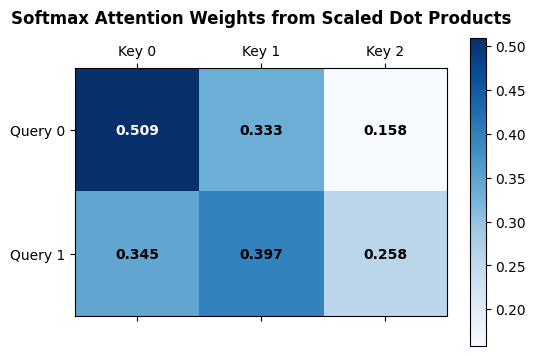

In [3]:
# Demonstrate Dot Product, Orthogonality, and Cosine Similarity
a = np.array([1.0, 2.0, 3.0])
b_similar = np.array([2.0, 4.0, 5.0])    # Similar direction
b_ortho = np.array([-3.0, 0.0, 1.0])     # Orthogonal (dot product = 0)
b_opposite = np.array([-1.0, -2.0, -3.0]) # Opposite direction

def cosine_similarity(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))

print("Vector a:", a)
print(f"a · b_similar:  {np.dot(a, b_similar):.2f}  | Cosine Similarity: {cosine_similarity(a, b_similar):.4f} (High Alignment)")
print(f"a · b_ortho:    {np.dot(a, b_ortho):.2f}  | Cosine Similarity: {cosine_similarity(a, b_ortho):.4f} (Orthogonal)")
print(f"a · b_opposite: {np.dot(a, b_opposite):.2f} | Cosine Similarity: {cosine_similarity(a, b_opposite):.4f} (Opposite)")

# Visualizing 2D Attention-Style Dot Products
queries = np.array([[1.0, 0.5], [0.2, 0.9]])
keys = np.array([[0.9, 0.4], [0.1, 0.8], [-0.7, 0.3]])

# Scaled Dot Product: Q @ K.T / sqrt(d)
d_k = queries.shape[1]
raw_scores = np.dot(queries, keys.T)
scaled_scores = raw_scores / np.sqrt(d_k)
attention_weights = np.exp(scaled_scores) / np.sum(np.exp(scaled_scores), axis=-1, keepdims=True)

fig, ax = plt.subplots(figsize=(6, 4))
cax = ax.matshow(attention_weights, cmap='Blues')
fig.colorbar(cax)
ax.set_xticks(range(3))
ax.set_yticks(range(2))
ax.set_xticklabels(['Key 0', 'Key 1', 'Key 2'])
ax.set_yticklabels(['Query 0', 'Query 1'])
for (i, j), z in np.ndenumerate(attention_weights):
    ax.text(j, i, f'{z:.3f}', ha='center', va='center', color='white' if z > 0.5 else 'black', fontweight='bold')
ax.set_title("Softmax Attention Weights from Scaled Dot Products", pad=15, fontweight='bold')
plt.show()

---
## 3. 🔄 Matrices as Linear Transformations

### 3.1 What is a Matrix?
A matrix $A \in \mathbb{R}^{m \times n}$ is not just a table of numbers — it is a **linear mapping (transformation)** from $\mathbb{R}^n$ to $\mathbb{R}^m$:

$$T(\mathbf{x}) = A\mathbf{x}$$

When $A$ multiplies a vector $\mathbf{x}$, it outputs a new vector $\mathbf{y}$ formed by taking a **linear combination of the columns of $A$**:

$$A\mathbf{x} = \begin{bmatrix} | & | & & | \\ \mathbf{a}_1 & \mathbf{a}_2 & \dots & \mathbf{a}_n \\ | & | & & | \end{bmatrix} \begin{bmatrix} x_1 \\ x_2 \\ \vdots \\ x_n \end{bmatrix} = x_1 \mathbf{a}_1 + x_2 \mathbf{a}_2 + \dots + x_n \mathbf{a}_n$$

### 3.2 Common 2D Geometric Transformations
For any 2D point $\begin{bmatrix} x \\ y \end{bmatrix}$, multiplying by $2 \times 2$ matrices transforms the space:

1. **Scaling:** $\begin{bmatrix} s_x & 0 \\ 0 & s_y \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix} = \begin{bmatrix} s_x x \\ s_y y \end{bmatrix}$
2. **Rotation by angle $\theta$:** $\begin{bmatrix} \cos(\theta) & -\sin(\theta) \\ \sin(\theta) & \cos(\theta) \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix}$
3. **Shear:** $\begin{bmatrix} 1 & k \\ 0 & 1 \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix} = \begin{bmatrix} x + ky \\ y \end{bmatrix}$

---

### 🚀 Neural Networks as Composed Linear Transformations
A deep neural network is a chain of parameterized matrix multiplications interleaved with non-linear activation functions $\sigma$:

$$\mathbf{h}^{(1)} = \sigma(W^{(1)} \mathbf{x} + \mathbf{b}^{(1)})$$
$$\mathbf{h}^{(2)} = \sigma(W^{(2)} \mathbf{h}^{(1)} + \mathbf{b}^{(2)})$$
$$\mathbf{\hat{y}} = W^{(3)} \mathbf{h}^{(2)} + \mathbf{b}^{(3)}$$

- The weight matrix $W$ rotates, stretches, and projects the representation space.
- The non-linearity $\sigma$ bends the space, enabling the network to learn non-linear decision boundaries.

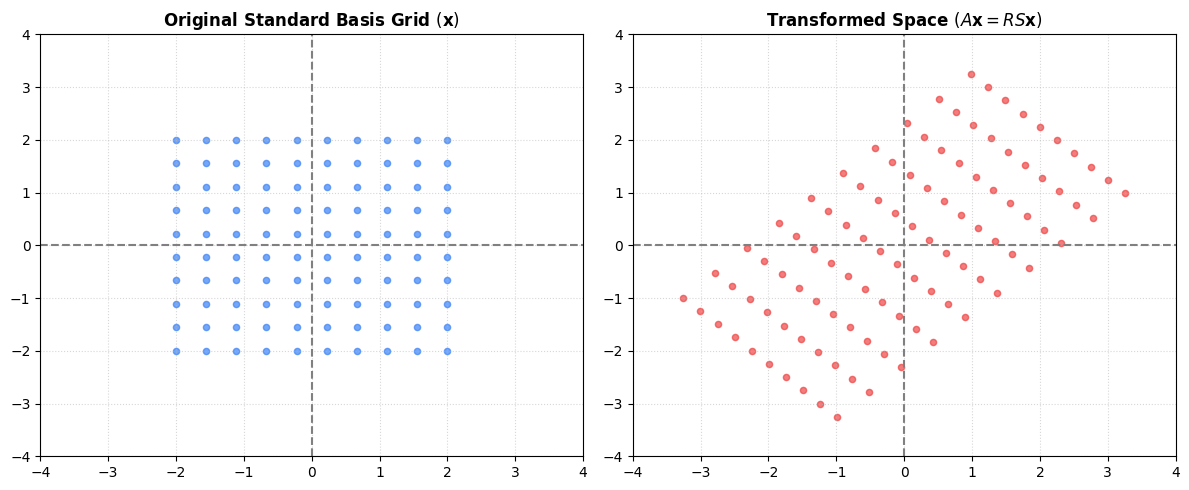

In [4]:
# Visualizing 2D Matrix Linear Transformation (Grid Deformation)
theta = np.pi / 4  # 45 degrees
R = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta),  np.cos(theta)]
])
S = np.array([[1.5, 0], [0, 0.8]]) # Scaling
A = R @ S # Combined Transformation: Scale then Rotate

# Create a 2D Grid
x = np.linspace(-2, 2, 10)
y = np.linspace(-2, 2, 10)
X, Y = np.meshgrid(x, y)
points = np.vstack([X.ravel(), Y.ravel()])

# Apply transformation
transformed_points = A @ points

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Original space
ax1.scatter(points[0], points[1], c='#3B82F6', s=20, alpha=0.7)
ax1.axhline(0, color='gray', linestyle='--')
ax1.axvline(0, color='gray', linestyle='--')
ax1.set_title("Original Standard Basis Grid $(\mathbf{x})$", fontweight='bold')
ax1.set_xlim(-4, 4); ax1.set_ylim(-4, 4); ax1.grid(True, linestyle=':', alpha=0.5)

# Transformed space
ax2.scatter(transformed_points[0], transformed_points[1], c='#EF4444', s=20, alpha=0.7)
ax2.axhline(0, color='gray', linestyle='--')
ax2.axvline(0, color='gray', linestyle='--')
ax2.set_title("Transformed Space $(A\mathbf{x} = RS\mathbf{x})$", fontweight='bold')
ax2.set_xlim(-4, 4); ax2.set_ylim(-4, 4); ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 4. 🔗 Linear Independence, Span & Multicollinearity

### 4.1 Linear Combination & Span
Given vectors $\{\mathbf{v}_1, \mathbf{v}_2, \dots, \mathbf{v}_k\}$, a **linear combination** is any vector formed by:
$$\mathbf{y} = c_1 \mathbf{v}_1 + c_2 \mathbf{v}_2 + \dots + c_k \mathbf{v}_k, \quad c_i \in \mathbb{R}$$

The **Span** is the set of all possible linear combinations reachable by these vectors:
$$\text{Span}(\mathbf{v}_1, \dots, \mathbf{v}_k) = \{ c_1 \mathbf{v}_1 + \dots + c_k \mathbf{v}_k \mid c_i \in \mathbb{R} \}$$

### 4.2 Linear Independence
A set of vectors is **linearly independent** if no vector in the set can be written as a linear combination of the others:
$$c_1 \mathbf{v}_1 + c_2 \mathbf{v}_2 + \dots + c_k \mathbf{v}_k = \mathbf{0} \quad \iff \quad c_1 = c_2 = \dots = c_k = 0$$

If any non-zero coefficients satisfy the equation, the vectors are **linearly dependent** (redundant).

---

### ⚠️ ML Pitfall: Multicollinearity in Regression
In linear models $\mathbf{y} = X\mathbf{w} + \epsilon$, the Ordinary Least Squares (OLS) closed-form solution is:
$$\mathbf{w}^* = (X^T X)^{-1} X^T \mathbf{y}$$

- If two features are linearly dependent (e.g., $x_2 = 2.5 x_1$), the columns of $X$ are not linearly independent.
- $X^T X$ becomes **singular** (determinant $= 0$) and cannot be inverted!
- In practice, near-linear dependence causes $X^T X$ to have eigenvalues close to $0$, causing the weights $\mathbf{w}^*$ to explode and become numerically unstable.

> 💡 **The Solution (Ridge Regularization / $L_2$):**  
> We add $\lambda I$ to the diagonal: $\mathbf{w}_{\text{ridge}} = (X^T X + \lambda I)^{-1} X^T \mathbf{y}$.  
> Because $\lambda > 0$, $(X^T X + \lambda I)$ is guaranteed to be strictly positive-definite, full-rank, and invertible!

In [5]:
# Demonstrate Multicollinearity and Ridge Invertibility
np.random.seed(42)
N = 100
# Feature x1
x1 = np.random.randn(N)
# Feature x2 is almost perfectly linearly dependent on x1
x2 = 2.0 * x1 + np.random.normal(0, 1e-4, N)
X = np.column_stack([x1, x2])

# Covariance matrix X^T X
XTX = X.T @ X
det_XTX = np.linalg.det(XTX)
cond_num = np.linalg.cond(XTX)

print("--- Multicollinearity Diagnostics ---")
print("X^T X Matrix:\n", XTX)
print(f"Determinant of X^T X: {det_XTX:.6e} (Nearly 0 -> Singular!)")
print(f"Condition Number:     {cond_num:.2e} (Extremely high -> Numerically unstable)")

# Regularized Ridge Inversion (XTX + lambda * I)
lambda_reg = 1.0
XTX_ridge = XTX + lambda_reg * np.eye(2)
print(f"Ridge Determinant:    {np.linalg.det(XTX_ridge):.4f} (Strictly Invertible & Stable!)")

--- Multicollinearity Diagnostics ---
X^T X Matrix:
 [[ 82.73062939 165.46006588]
 [165.46006588 330.91774689]]
Determinant of X^T X: 7.310798e-05 (Nearly 0 -> Singular!)
Condition Number:     2.34e+09 (Extremely high -> Numerically unstable)
Ridge Determinant:    414.6484 (Strictly Invertible & Stable!)


---
## 5. 📉 Matrix Rank & Low-Rank Adaptation (LoRA)

### 5.1 Matrix Rank
The **Rank** of a matrix $A \in \mathbb{R}^{m \times n}$, denoted $\text{rank}(A)$, is the number of linearly independent columns (or rows).
$$\text{rank}(A) \le \min(m, n)$$

- **Full Rank:** $\text{rank}(A) = \min(m, n)$. The matrix utilizes the full capacity of its dimensional space.
- **Rank Deficient (Low-Rank):** $\text{rank}(A) < \min(m, n)$. The columns span a lower-dimensional subspace.

---

### 🚀 Modern AI Highlight: LoRA (Low-Rank Adaptation)
When fine-tuning large language models (e.g. LLaMA, GPT), updating the full weight matrix $W_0 \in \mathbb{R}^{d \times k}$ ($4096 \times 4096 \approx 16.7\text{M}$ parameters per layer) is computationally expensive.

**The LoRA Hypothesis (Hu et al., 2021):**  
The weight update $\Delta W$ during task-specific adaptation has a very low **intrinsic rank** $r \ll \min(d, k)$.

$$\Delta W = B \cdot A$$
where $B \in \mathbb{R}^{d \times r}$ and $A \in \mathbb{R}^{r \times k}$ with rank $r \in \{4, 8, 16, 32\}$.

```
      Full Weight Update ΔW              LoRA Factorization: B × A
       ┌──────────────────┐               ┌──┐
       │                  │               │  │       ┌──────────────────┐
       │   d × k matrix   │      =        │d │   ×   │   r × k matrix   │ (A)
       │ (16.7M params)   │               │×r│       └──────────────────┘
       │                  │               │  │ (B)
       └──────────────────┘               └──┘
```

#### Parameter Savings Calculation:
- **Full Fine-Tuning ($d=4096, k=4096$):** $4096 \times 4096 = 16,777,216$ parameters.
- **LoRA ($r=16$):** $(4096 \times 16) + (16 \times 4096) = 131,072$ parameters.
- **Reduction:** **99.2% fewer parameters** trained and stored in memory!

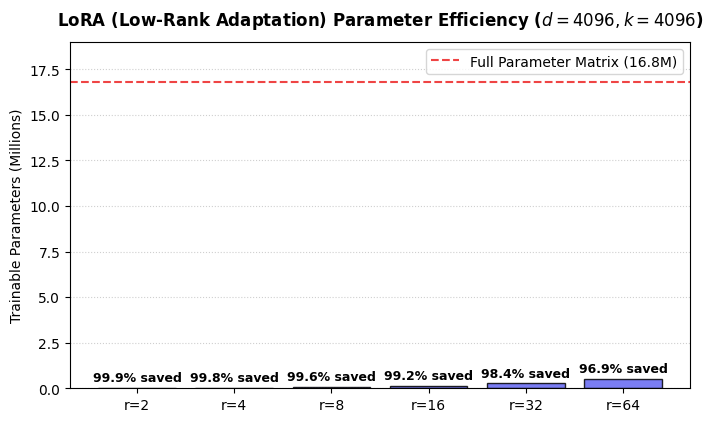

In [6]:
# Low-Rank Matrix Factorization & LoRA Parameter Simulation
d = 4096
k = 4096
ranks = [2, 4, 8, 16, 32, 64]

full_params = d * k
lora_params = [(d * r + r * k) for r in ranks]
savings = [(1 - (p / full_params)) * 100 for p in lora_params]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([f'r={r}' for r in ranks], [p / 1e6 for p in lora_params], color='#6366F1', edgecolor='black', alpha=0.85)
ax.axhline(full_params / 1e6, color='#EF4444', linestyle='--', label=f'Full Parameter Matrix ({full_params/1e6:.1f}M)')

for bar, sav in zip(bars, savings):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.2, f'{sav:.1f}% saved', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_ylabel("Trainable Parameters (Millions)", fontsize=10)
ax.set_title("LoRA (Low-Rank Adaptation) Parameter Efficiency ($d=4096, k=4096$)", fontsize=12, fontweight='bold', pad=12)
ax.set_ylim(0, 19)
ax.legend()
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

---
## 6. 📐 Vector & Matrix Projections

### 6.1 Vector Projection
The **orthogonal projection** of vector $\mathbf{a}$ onto vector $\mathbf{b}$ drops a perpendicular line from $\mathbf{a}$ onto the line spanned by $\mathbf{b}$:

$$\text{proj}_{\mathbf{b}}(\mathbf{a}) = \hat{\mathbf{a}} = \left(\frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{b}\|^2}\right) \mathbf{b} = \left(\frac{\mathbf{a}^T \mathbf{b}}{\mathbf{b}^T \mathbf{b}}\right) \mathbf{b}$$

The **residual error vector** $\mathbf{e} = \mathbf{a} - \hat{\mathbf{a}}$ is strictly orthogonal to $\mathbf{b}$:
$$\mathbf{e} \cdot \mathbf{b} = 0$$

### 6.2 Matrix Projection & Ordinary Least Squares (OLS)
When projecting a vector $\mathbf{y}$ onto the column space of a matrix $X$ (denoted $\text{Col}(X)$), the projection matrix $P$ is:

$$P = X(X^T X)^{-1} X^T$$

- **Projection Operator:** $\mathbf{\hat{y}} = P \mathbf{y} = X \mathbf{w}^*$
- **Idempotence Property:** $P^2 = P$ (Projecting an already projected vector changes nothing).
- **Symmetry Property:** $P^T = P$.

> 💡 **Geometric Intuition of Linear Regression:**  
> The target vector $\mathbf{y}$ does not lie in the column space of $X$. Finding the best weights $\mathbf{w}^*$ is geometrically equivalent to finding the point $\mathbf{\hat{y}}$ in $\text{Col}(X)$ closest to $\mathbf{y}$, which is the **orthogonal projection**!

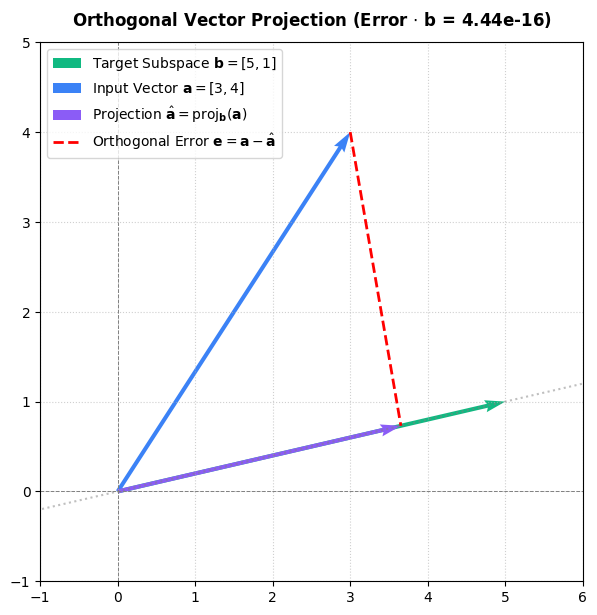

In [7]:
# Visualizing 2D Vector Orthogonal Projection
a = np.array([3.0, 4.0])
b = np.array([5.0, 1.0])

# Orthogonal Projection: proj_b(a) = ((a . b) / (b . b)) * b
proj_a_b = (np.dot(a, b) / np.dot(b, b)) * b
error_vec = a - proj_a_b

fig, ax = plt.subplots(figsize=(7, 7))

# Plot vectors
ax.quiver(0, 0, b[0], b[1], angles='xy', scale_units='xy', scale=1, color='#10B981', label=r'Target Subspace $\mathbf{b} = [5, 1]$')
ax.quiver(0, 0, a[0], a[1], angles='xy', scale_units='xy', scale=1, color='#3B82F6', label=r'Input Vector $\mathbf{a} = [3, 4]$')
ax.quiver(0, 0, proj_a_b[0], proj_a_b[1], angles='xy', scale_units='xy', scale=1, color='#8B5CF6', label=r'Projection $\hat{\mathbf{a}} = \mathrm{proj}_{\mathbf{b}}(\mathbf{a})$')

# Plot orthogonal error line
ax.plot([a[0], proj_a_b[0]], [a[1], proj_a_b[1]], 'r--', linewidth=2, label=r'Orthogonal Error $\mathbf{e} = \mathbf{a} - \hat{\mathbf{a}}$')

# Extend line of b for visualization
line_t = np.linspace(-0.5, 1.5, 100)
ax.plot(line_t * b[0], line_t * b[1], color='gray', linestyle=':', alpha=0.5)

ax.set_xlim(-1, 6); ax.set_ylim(-1, 5)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.7)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.7)
ax.grid(True, linestyle=':', alpha=0.6)
ax.set_title(f"Orthogonal Vector Projection (Error $\cdot$ b = {np.dot(error_vec, b):.2e})", fontsize=12, fontweight='bold', pad=12)
ax.legend(loc='upper left')
plt.show()

---
## 7. 🔮 Eigenvalues & Eigenvectors

### 7.1 Mathematical Formulation
For a square matrix $A \in \mathbb{R}^{n \times n}$, an **eigenvector** $\mathbf{v} \neq \mathbf{0}$ is a special vector whose direction is unchanged when multiplied by $A$. It is merely scaled by the **eigenvalue** $\lambda$:

$$A\mathbf{v} = \lambda \mathbf{v}$$

Rearranging gives the characteristic equation:
$$(A - \lambda I)\mathbf{v} = \mathbf{0} \quad \implies \quad \det(A - \lambda I) = 0$$

### 7.2 Geometric Meaning
Most vectors rotate and change length when transformed by matrix $A$.  
**Eigenvectors are the invariant axes of the transformation** — they do not rotate at all; they only get stretched or compressed by factor $\lambda$.

---

### 🚀 Key AI Application: Principal Component Analysis (PCA)
In high-dimensional AI data (images, document embeddings):
1. We compute the empirical **Sample Covariance Matrix**:
   $$\Sigma = \frac{1}{N - 1} X^T X \in \mathbb{R}^{d \times d}$$
2. We perform **Eigendecomposition** on $\Sigma$:
   $$\Sigma \mathbf{v}_i = \lambda_i \mathbf{v}_i$$
3. The eigenvectors $\mathbf{v}_1, \mathbf{v}_2, \dots$ represent the **Principal Components** (directions of maximum variance in the dataset).
4. The eigenvalues $\lambda_1 \ge \lambda_2 \ge \dots$ represent the amount of variance explained along each axis.

--- Eigendecomposition of Covariance Matrix ---
Eigenvalue 1 (Max Variance): 9.296 -> Vector: [-0.84144894 -0.54033663]
Eigenvalue 2 (Min Variance): 1.151 -> Vector: [ 0.54033663 -0.84144894]


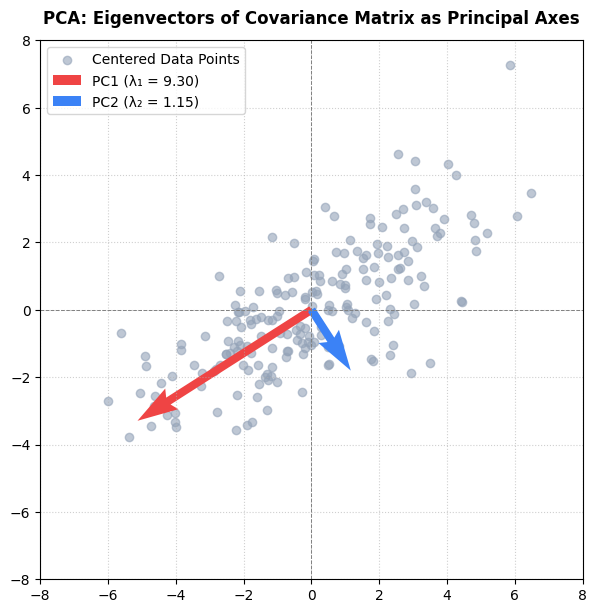

In [8]:
# Demonstrate Eigendecomposition & PCA on 2D Synthetic Data
np.random.seed(42)
# Generate correlated Gaussian cloud
X_orig = np.random.randn(200, 2)
Transform = np.array([[2.5, 1.2], [0.8, 1.8]])
X = X_orig @ Transform.T
X_centered = X - np.mean(X, axis=0)

# Compute Covariance Matrix and Eigendecomposition
cov_matrix = np.cov(X_centered, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Sort eigenvectors by descending eigenvalue
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("--- Eigendecomposition of Covariance Matrix ---")
print(f"Eigenvalue 1 (Max Variance): {eigenvalues[0]:.3f} -> Vector: {eigenvectors[:, 0]}")
print(f"Eigenvalue 2 (Min Variance): {eigenvalues[1]:.3f} -> Vector: {eigenvectors[:, 1]}")

# Visualization
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X_centered[:, 0], X_centered[:, 1], c='#94A3B8', alpha=0.6, label='Centered Data Points')

# Plot Eigenvector axes scaled by their standard deviation (sqrt(eigenvalue))
origin = [0, 0]
v1 = eigenvectors[:, 0] * np.sqrt(eigenvalues[0]) * 2
v2 = eigenvectors[:, 1] * np.sqrt(eigenvalues[1]) * 2

ax.quiver(*origin, v1[0], v1[1], angles='xy', scale_units='xy', scale=1, color='#EF4444', width=0.015, label=f'PC1 (λ₁ = {eigenvalues[0]:.2f})')
ax.quiver(*origin, v2[0], v2[1], angles='xy', scale_units='xy', scale=1, color='#3B82F6', width=0.015, label=f'PC2 (λ₂ = {eigenvalues[1]:.2f})')

ax.set_xlim(-8, 8); ax.set_ylim(-8, 8)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.7)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.7)
ax.grid(True, linestyle=':', alpha=0.6)
ax.set_title("PCA: Eigenvectors of Covariance Matrix as Principal Axes", fontsize=12, fontweight='bold', pad=12)
ax.legend()
plt.show()

---
## 8. 📚 Linear Algebra for AI: Quick Reference Cheat Sheet

| Math Operation | Equation | Deep Learning Usage |
| :--- | :--- | :--- |
| **Vector Addition** | $\mathbf{z} = \mathbf{x} + \mathbf{y}$ | ResNet Skip Connections ($x + f(x)$), Positional Encodings |
| **$L_2$ Norm** | $\|\mathbf{x}\|_2 = \sqrt{\mathbf{x}^T \mathbf{x}}$ | Weight Decay Regularization, Embedding Normalization |
| **Dot Product** | $\mathbf{a}^T \mathbf{b} = \sum a_i b_i$ | Self-Attention Scores ($Q K^T$), Cosine Similarity |
| **Matrix-Vector Multiply** | $\mathbf{y} = W\mathbf{x} + \mathbf{b}$ | Dense / Linear Neural Network Layer |
| **Matrix Multiply** | $C = A B$ | Multi-Head Attention, Batch Matrix Multiplication (BMM) |
| **Matrix Inversion** | $A^{-1} A = I$ | Ordinary Least Squares, Kalman Filters, Bayesian Updates |
| **Rank Decomposition** | $\Delta W = B A, r \ll d$ | LoRA (Low-Rank Adaptation) for LLM fine-tuning |
| **Orthogonal Projection** | $P = X(X^T X)^{-1} X^T$ | Linear Regression, PCA Subspace Projection |
| **Eigendecomposition** | $A\mathbf{v} = \lambda \mathbf{v}$ | PCA, Graph Neural Networks (Spectral Graph Convolutions) |

---
### 🎓 Summary
Every AI model you build or fine-tune translates high-level concepts into this linear algebra pipeline.  
Keep these geometric and algebraic intuitions handy as you advance into **Phase 1: Math Foundations**!